# Aircraft maintenance: experiments and results

**Main presentation notebook for Emanuele.** Runs the current core implementation,
saves checkpoints, evaluation data and figures, and compares single-agent,
multi-agent reinforcement learning (MARL), and hierarchical reinforcement learning (HRL) controllers. Detailed teaching material remains in
`Comprehensive_RL_HRL_Maintenance_Tutorial.ipynb`; implementation details are in
the [updated code report](docs/reports/code_report_2026-10-26.pdf).

Run all cells in order. The configured runs are exploratory comparisons;
their rankings do not establish convergence or operational validity.

## 1. Setup and experiment settings

All registered methods are tested with seven aircraft, except MAXQ, which is
restricted to one aircraft. A separate one-aircraft panel compares **all methods**
with MAXQ under the same fleet size. Each trained method uses three initialization
seeds and the same held-out evaluation seeds. Settings and the core-source hash
are saved with every run. Increase `TRAIN_DAYS` for a longer study.

In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import asdict
from datetime import datetime, timezone
import csv, gzip, hashlib, html, json, platform, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

PROJECT = next(p for p in (Path.cwd(), Path.cwd().parent)
               if (p / 'maintenance_tutorial_annotated_core.py').is_file())
sys.path.insert(0, str(PROJECT))
import maintenance_tutorial_annotated_core as core

TRAIN_DAYS = 1024
ROLLOUT_SIZE = 128
TRAIN_SEEDS = [0, 1000, 2000]
EVAL_SEEDS = list(range(10000, 10020))
HORIZON = 90
PANELS = {'fleet_7': core.Config(aircraft=7, horizon=HORIZON),
          'single_1': core.Config(aircraft=1, horizon=HORIZON)}
ALL_METHODS = tuple(core.ALL_LEARNED_METHODS)
METHODS = {panel: [m for m in ALL_METHODS if m != 'maxq' or cfg.aircraft == 1]
           for panel, cfg in PANELS.items()}
SOURCE_HASH = hashlib.sha256((PROJECT / core.__file__).read_bytes()).hexdigest()
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
RUN = PROJECT / 'results' / ('presentation_' + RUN_ID)
for folder in ('checkpoints', 'training_logs', 'data', 'plots'):
    (RUN / folder).mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
try:
    SOURCE_COMMIT = subprocess.check_output(
        ['git', 'rev-parse', 'HEAD'], cwd=PROJECT, text=True).strip()
except (OSError, subprocess.CalledProcessError):
    SOURCE_COMMIT = None

def json_default(value):
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    raise TypeError(type(value).__name__)

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, default=json_default, allow_nan=False),
                    encoding='utf-8')

manifest = {'run_id': RUN_ID, 'core_sha256': SOURCE_HASH, 'source_commit': SOURCE_COMMIT,
            'observation_version': core.OBSERVATION_VERSION,
            'train_days_per_seed': TRAIN_DAYS, 'rollout_size': ROLLOUT_SIZE,
            'training_seeds': TRAIN_SEEDS, 'evaluation_seeds': EVAL_SEEDS,
            'panels': {p: asdict(c) for p, c in PANELS.items()}, 'methods': METHODS,
            'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                         'torch': str(torch.__version__), 'pandas': pd.__version__},
            'device': 'CPU; one Torch thread', 'status': 'running',
            'interpretation': 'exploratory fixed-budget comparison; not convergence evidence'}
save_json(RUN / 'manifest.json', manifest)
display(pd.DataFrame([{'panel': p, 'aircraft': c.aircraft, 'horizon_days': c.horizon,
                       'learned_methods': len(METHODS[p]), 'days_per_training_seed': TRAIN_DAYS,
                       'training_seeds': len(TRAIN_SEEDS), 'evaluation_episodes_per_model': len(EVAL_SEEDS)}
                      for p, c in PANELS.items()]))
print('Results:', RUN.relative_to(PROJECT))
print('Core SHA-256:', SOURCE_HASH)

,panel,aircraft,horizon_days,learned_methods,days_per_training_seed,training_seeds,evaluation_episodes_per_model
0,fleet_7,7,90,17,1024,3,20
1,single_1,1,90,18,1024,3,20


Results: results\presentation_20261026T143049Z
Core SHA-256: a626792817b8f870a1ebe644f25cdf8783d97ed16eaff8652b7fc4060aec7628


## 2. Controller groups and comparison contract

MAPPO means multi-agent proximal policy optimization; DCMAC/DDMAC mean deep
centralized/decentralized multi-agent actor–critic. They share a replacement-request
broker, but differ in actor information, parameter sharing and learning updates.
The new aircraft hierarchy methods use a smaller 22-entry replacement catalog.
Original fleet controllers also learn resource selections.

`hrl_flat` and `planning_hierarchy` provide the closest flat-versus-staged comparison.
Scores across all methods also reflect different authority, decision timing and
objectives. Paired evaluation seeds give matched initial scenarios; policy-dependent
random-number consumption means they do not guarantee identical event histories.
The physical model remains synthetic, with the flight-condition upgrade pending.

In [2]:
MARL = ['mappo_aircraft', 'mappo_component', 'dcmac_aircraft',
        'ddmac_aircraft', 'dcmac_component', 'ddmac_component']
HRL = ['options', 'learned_options', 'concurrent_options', 'planning_hierarchy',
       'aggregate_targets', 'maxq', 'option_critic', 'hierarchical_vdn']
FAMILY = {m: ('MARL' if m in MARL else 'HRL' if m in HRL else
              'Catalog comparator' if m == 'hrl_flat' else 'Single-agent') for m in ALL_METHODS}
GROUPS = {'Original daily policies': ['flat', 'conditional', 'shared'],
          'Original fleet options': ['options', 'learned_options'],
          'MAPPO': ['mappo_aircraft', 'mappo_component'],
          'DCMAC / DDMAC': ['dcmac_aircraft', 'ddmac_aircraft', 'dcmac_component', 'ddmac_component'],
          'Aircraft planning policies': ['concurrent_options', 'planning_hierarchy', 'aggregate_targets', 'hrl_flat'],
          'Other hierarchies': ['maxq', 'option_critic', 'hierarchical_vdn']}
assert len(ALL_METHODS) == len(set(ALL_METHODS)) == 18
assert set(sum(GROUPS.values(), [])) == set(ALL_METHODS)
display(pd.DataFrame([{'method': m, 'family': FAMILY[m],
                       'fleet_7': m in METHODS['fleet_7'], 'single_1': True}
                      for m in ALL_METHODS]))

,method,family,fleet_7,single_1
0,flat,Single-agent,True,True
1,conditional,Single-agent,True,True
2,shared,Single-agent,True,True
3,options,HRL,True,True
4,learned_options,HRL,True,True
5,mappo_aircraft,MARL,True,True
6,mappo_component,MARL,True,True
7,dcmac_aircraft,MARL,True,True
8,ddmac_aircraft,MARL,True,True
9,dcmac_component,MARL,True,True


## 3. Train, save and evaluate

Each model is trained once per seed and saved before held-out evaluation. A
checkpoint reload must reproduce the first evaluation episode. Completed runs
are written immediately; failures stop execution instead of silently removing a
method from the comparison. Large checkpoints and full training logs stay local;
compact evaluation data and plots accompany the notebook on GitHub.

In [3]:
evaluation_rows, run_rows, curve_rows = [], [], []

def persist_tables():
    pd.DataFrame(evaluation_rows).to_csv(RUN / 'data/evaluation.csv', index=False)
    pd.DataFrame(run_rows).to_csv(RUN / 'data/training_runs.csv', index=False)
    pd.DataFrame(curve_rows).to_csv(RUN / 'data/training_episodes.csv', index=False)
    save_json(RUN / 'progress.json', {'completed_training_runs': len(run_rows),
              'expected_training_runs': sum(map(len, METHODS.values())) * len(TRAIN_SEEDS),
              'latest': run_rows[-1] if run_rows else None})

def run_panel(panel):
    cfg = PANELS[panel]
    for record in core.evaluate(cfg, 'threshold', seeds=EVAL_SEEDS):
        evaluation_rows.append({'panel': panel, 'method': 'threshold',
                                 'training_seed': -1, 'family': 'Fixed rule', **record})
    persist_tables()
    for method in METHODS[panel]:
        for seed in TRAIN_SEEDS:
            key = f'{panel}__{method}__seed{seed}'
            start = time.perf_counter()
            model, logs, days = core.train(cfg, method, steps=TRAIN_DAYS,
                                           seed=seed, rollout_size=ROLLOUT_SIZE)
            seconds = time.perf_counter() - start
            assert days == TRAIN_DAYS, (method, days)
            assert all(torch.isfinite(p).all() for p in model.parameters())
            checkpoint = RUN / 'checkpoints' / (key + '.pt')
            torch.save({'state_dict': model.state_dict(), 'config': asdict(cfg),
                        'method': method, 'training_seed': seed, 'simulated_days': days,
                        'observation_version': core.OBSERVATION_VERSION,
                        'core_sha256': SOURCE_HASH}, checkpoint)
            with gzip.open(RUN / 'training_logs' / (key + '.json.gz'), 'wt', encoding='utf-8') as handle:
                json.dump(logs, handle, default=json_default, allow_nan=False)
            model.eval()
            evaluation = core.evaluate(cfg, method, model, seeds=EVAL_SEEDS)
            loaded_cfg, loaded_method, restored = core.load_checkpoint(checkpoint)
            assert loaded_cfg == cfg and loaded_method == method
            assert core.evaluate(cfg, method, restored, seeds=EVAL_SEEDS[:1]) == evaluation[:1]
            for record in evaluation:
                evaluation_rows.append({'panel': panel, 'method': method,
                                         'training_seed': seed, 'family': FAMILY[method], **record})
            for record in logs:
                if 'return' in record and record.get('record_type', 'episode') == 'episode':
                    curve_rows.append({'panel': panel, 'method': method, 'training_seed': seed,
                                        'simulated_days': record['simulated_days'],
                                        'episode_return': record['return']})
            run_rows.append({'panel': panel, 'method': method, 'training_seed': seed,
                             'simulated_days': days, 'training_seconds': seconds,
                             'parameters': sum(p.numel() for p in model.parameters()),
                             'checkpoint': str(checkpoint.relative_to(RUN)),
                             'core_sha256': SOURCE_HASH, 'reload_verified': True})
            persist_tables()
            print(f'{panel}: {method}, seed {seed}, {days} days, {seconds:.1f}s; saved and verified', flush=True)

run_panel('fleet_7')

fleet_7: flat, seed 0, 1024 days, 10.5s; saved and verified


fleet_7: flat, seed 1000, 1024 days, 9.5s; saved and verified


fleet_7: flat, seed 2000, 1024 days, 8.8s; saved and verified


fleet_7: conditional, seed 0, 1024 days, 8.6s; saved and verified


fleet_7: conditional, seed 1000, 1024 days, 9.1s; saved and verified


...

fleet_7: hierarchical_vdn, seed 1000, 1024 days, 7.6s; saved and verified


fleet_7: hierarchical_vdn, seed 2000, 1024 days, 7.1s; saved and verified


fleet_7: hrl_flat, seed 0, 1024 days, 5.9s; saved and verified


fleet_7: hrl_flat, seed 1000, 1024 days, 4.9s; saved and verified


fleet_7: hrl_flat, seed 2000, 1024 days, 4.9s; saved and verified


### One-aircraft comparison including MAXQ

This panel uses the same training budget, evaluation seeds and horizon for every
method. It is reported separately: single-aircraft performance is not a fleet
scalability result.

In [4]:
run_panel('single_1')

single_1: flat, seed 0, 1024 days, 3.6s; saved and verified


single_1: flat, seed 1000, 1024 days, 3.4s; saved and verified


single_1: flat, seed 2000, 1024 days, 3.3s; saved and verified


single_1: conditional, seed 0, 1024 days, 3.8s; saved and verified


single_1: conditional, seed 1000, 1024 days, 3.5s; saved and verified


...

single_1: hierarchical_vdn, seed 1000, 1024 days, 2.7s; saved and verified


single_1: hierarchical_vdn, seed 2000, 1024 days, 2.8s; saved and verified


single_1: hrl_flat, seed 0, 1024 days, 1.2s; saved and verified


single_1: hrl_flat, seed 1000, 1024 days, 1.3s; saved and verified


single_1: hrl_flat, seed 2000, 1024 days, 1.2s; saved and verified


## 4. Held-out results

Rank by mean **environment return**, then inspect availability, cost and failures.
Return is the simulator's composite objective, not a safety certificate. Mean and
standard deviation (SD) below are computed across training seeds after averaging each
seed's evaluation episodes. The threshold rule has no training-seed variation;
its zero error bar does not mean zero environmental uncertainty.

In [5]:
evaluation = pd.DataFrame(evaluation_rows)
runs = pd.DataFrame(run_rows)
curves = pd.DataFrame(curve_rows)
expected = sum((len(methods) * len(TRAIN_SEEDS) + 1) * len(EVAL_SEEDS)
               for methods in METHODS.values())
assert len(evaluation) == expected
assert not evaluation.duplicated(['panel', 'method', 'training_seed', 'seed']).any()
assert np.isfinite(evaluation[['return', 'cost', 'availability', 'flight_failures']]).all().all()
assert evaluation['availability'].between(0, 1).all()
assert runs['reload_verified'].all()
for panel, cfg in PANELS.items():
    mask = evaluation.panel.eq(panel)
    evaluation.loc[mask, 'cost_per_aircraft_day'] = evaluation.loc[mask, 'cost'] / (cfg.aircraft * cfg.horizon)
metrics = ['return', 'availability', 'cost_per_aircraft_day', 'flight_failures',
           'rejections', 'replacements']
seed_means = evaluation.groupby(['panel', 'method', 'training_seed'])[metrics].mean().reset_index()
summary = seed_means.groupby(['panel', 'method'])[metrics].agg(['mean', 'std'])
summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
summary = summary.reset_index().fillna(0)
timing = runs.groupby(['panel', 'method'])[['training_seconds', 'parameters']].mean().reset_index()
summary = summary.merge(timing, on=['panel', 'method'], how='left')
summary['family'] = summary.method.map({**FAMILY, 'threshold': 'Fixed rule'})
summary['rank_by_return'] = summary.groupby('panel').return_mean.rank(method='min', ascending=False).astype(int)
summary = summary.sort_values(['panel', 'rank_by_return', 'method'])
summary.to_csv(RUN / 'data/summary.csv', index=False)
seed_means.to_csv(RUN / 'data/seed_means.csv', index=False)
evaluation.to_csv(RUN / 'data/evaluation.csv', index=False)

def show_results(panel):
    table = summary[summary.panel.eq(panel)][['rank_by_return', 'method', 'family',
        'return_mean', 'return_std', 'availability_mean', 'cost_per_aircraft_day_mean',
        'flight_failures_mean', 'training_seconds']].copy()
    display(Markdown(f'### {panel}: ranked evaluation results'))
    display(table.round(3).reset_index(drop=True))

show_results('fleet_7')
show_results('single_1')

### fleet_7: ranked evaluation results

,rank_by_return,method,family,return_mean,return_std,availability_mean,cost_per_aircraft_day_mean,flight_failures_mean,training_seconds
0,1,hierarchical_vdn,HRL,89.834,0.004,0.999,0.007,0.0,7.452
1,2,conditional,Single-agent,89.812,0.013,0.999,0.010,0.0,8.997
2,3,flat,Single-agent,77.931,20.508,0.951,0.854,0.0,9.574
3,4,learned_options,HRL,66.106,0.458,0.856,1.215,0.0,4.695
4,5,shared,Single-agent,65.278,21.282,0.904,1.783,0.0,11.826
5,6,threshold,Fixed rule,60.678,0.000,0.815,1.410,0.0,NaN
6,7,options,HRL,51.139,9.003,0.756,1.876,0.0,3.363
7,8,option_critic,HRL,48.337,3.829,0.714,1.772,0.0,7.503
8,9,aggregate_targets,HRL,48.222,2.469,0.714,1.785,0.0,5.820
9,10,concurrent_options,HRL,48.191,0.000,0.714,1.788,0.0,4.853


### single_1: ranked evaluation results

,rank_by_return,method,family,return_mean,return_std,availability_mean,cost_per_aircraft_day_mean,flight_failures_mean,training_seconds
0,1,aggregate_targets,HRL,90.000,0.000,1.000,0.000,0.0,1.883
1,1,concurrent_options,HRL,90.000,0.000,1.000,0.000,0.0,1.529
2,1,conditional,Single-agent,90.000,0.000,1.000,0.000,0.0,3.548
3,1,dcmac_aircraft,MARL,90.000,0.000,1.000,0.000,0.0,5.756
4,1,dcmac_component,MARL,90.000,0.000,1.000,0.000,0.0,5.177
5,1,ddmac_aircraft,MARL,90.000,0.000,1.000,0.000,0.0,5.221
6,1,ddmac_component,MARL,90.000,0.000,1.000,0.000,0.0,8.251
7,1,flat,Single-agent,90.000,0.000,1.000,0.000,0.0,3.443
8,1,hierarchical_vdn,HRL,90.000,0.000,1.000,0.000,0.0,2.812
9,1,hrl_flat,Catalog comparator,90.000,0.000,1.000,0.000,0.0,1.248


## 5. Saved plots

Error bars show variation between trained seeds. Training curves use completed
episode returns, smoothed over five episodes within each seed. They measure
training behavior, whereas the ranked tables use held-out deterministic evaluation.

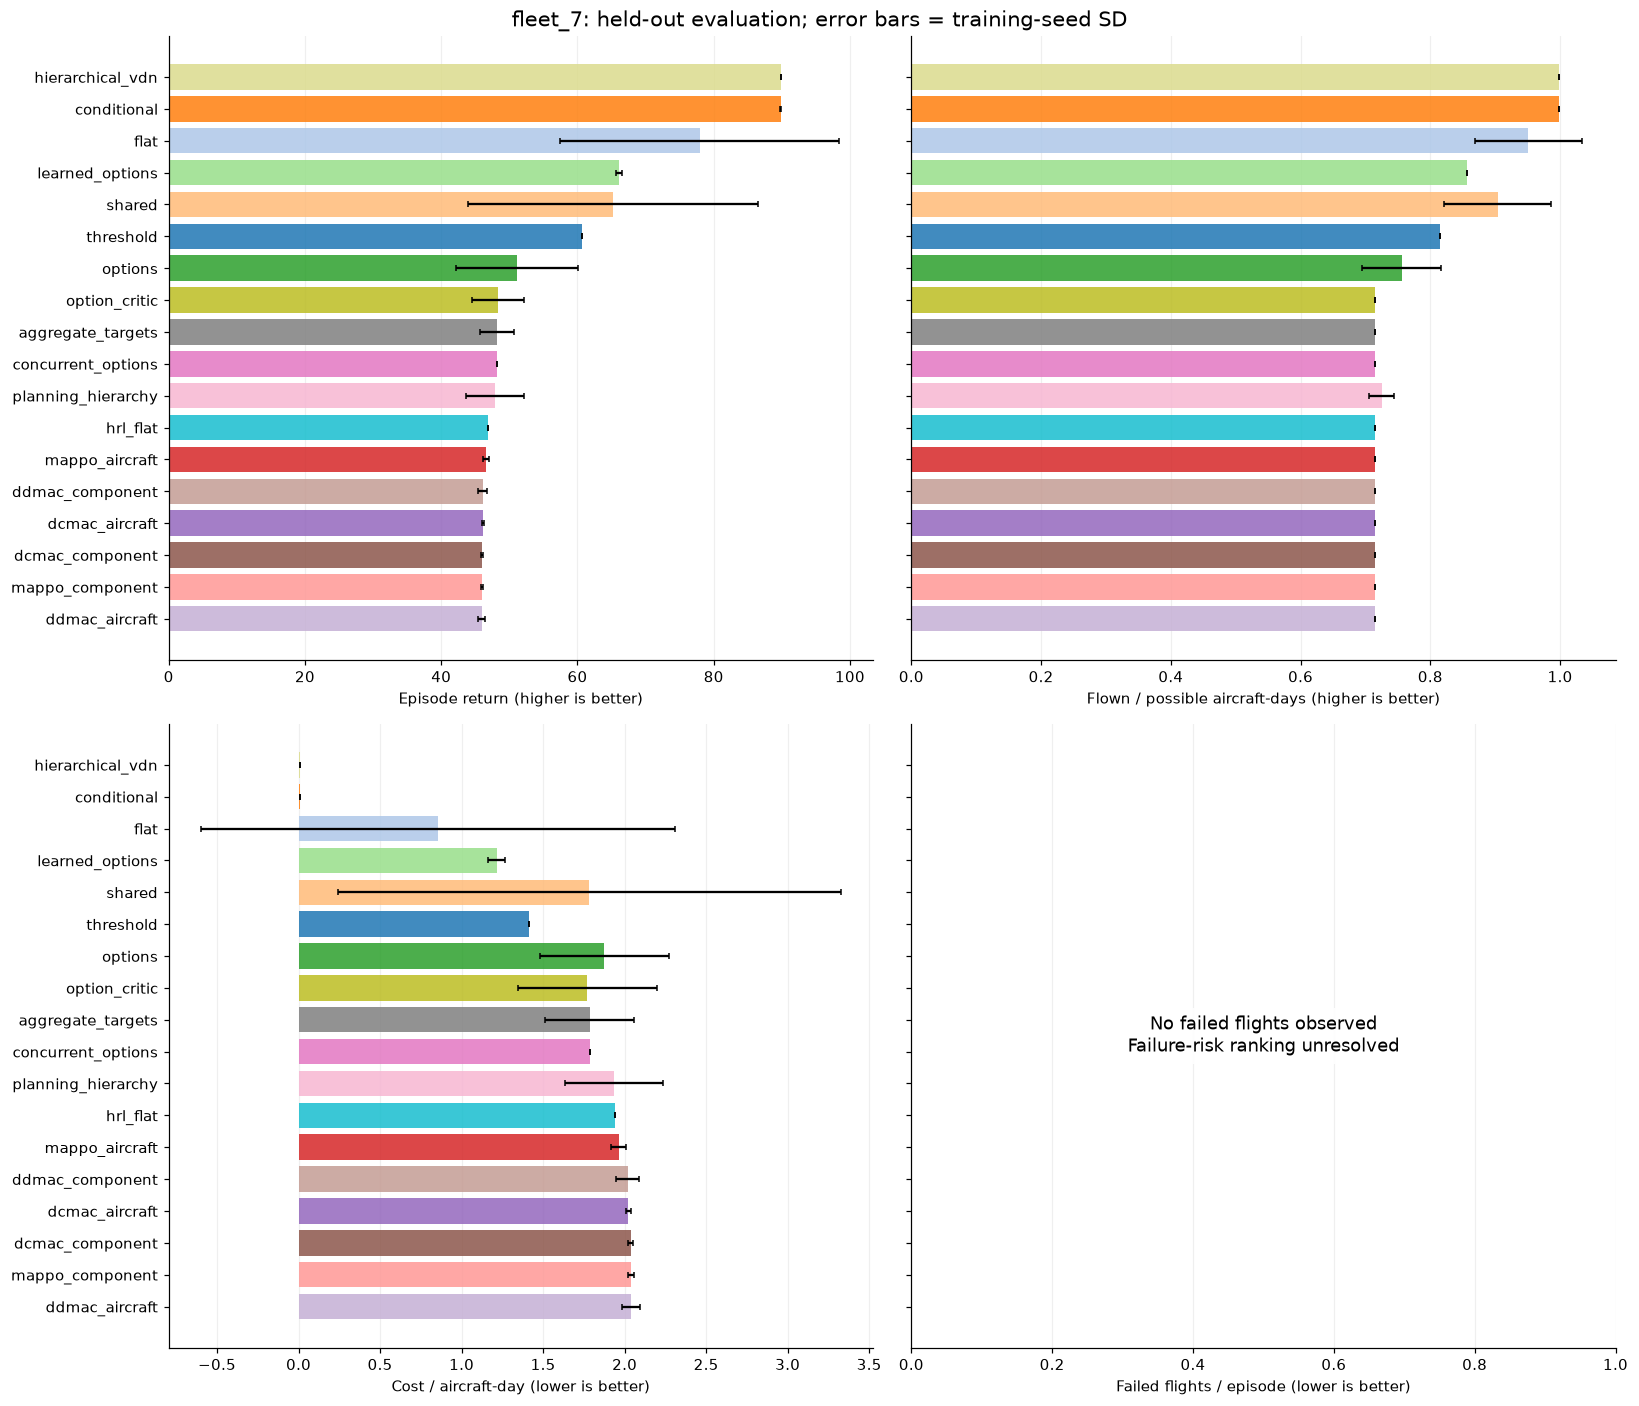

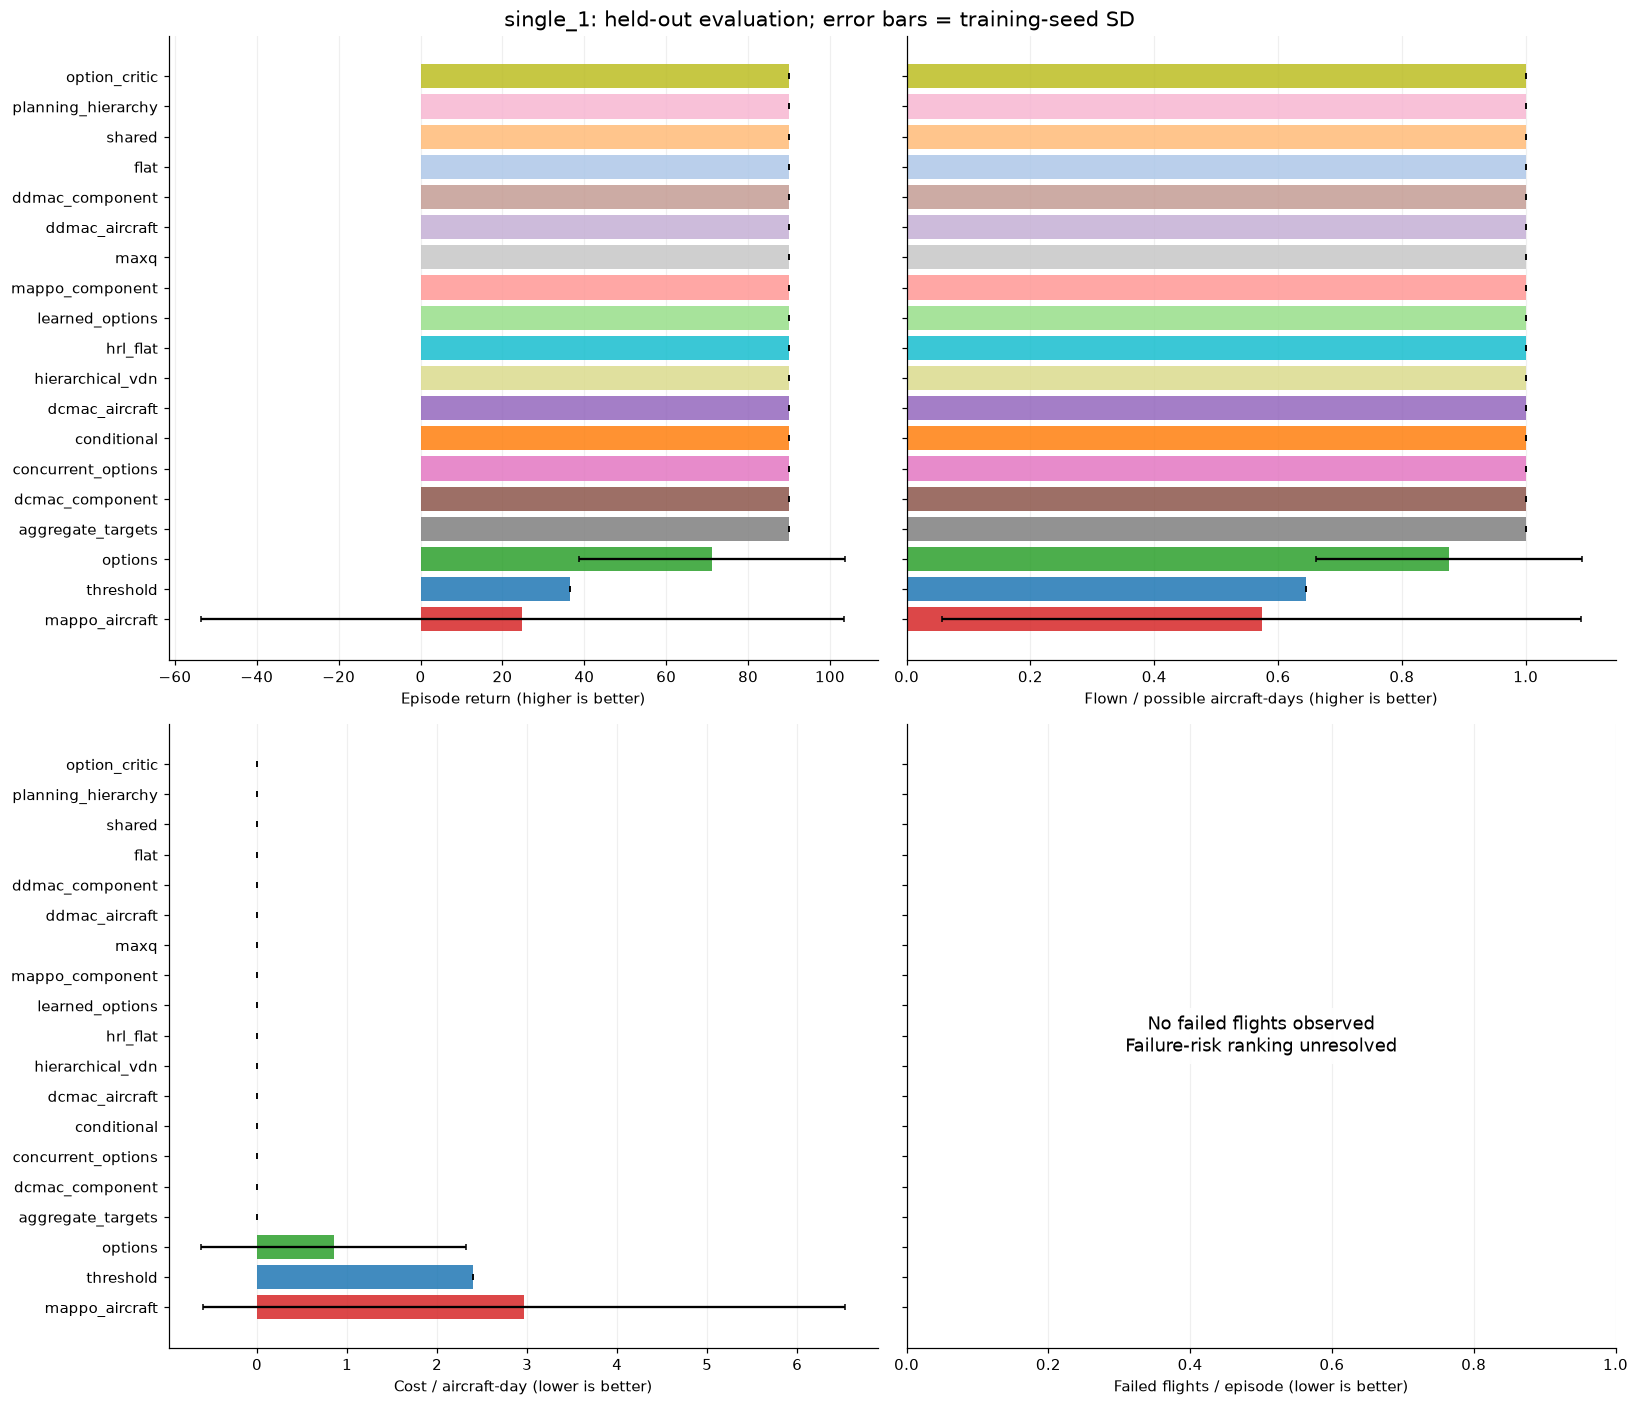

In [6]:
COLORS = {m: plt.get_cmap('tab20')(i) for i, m in enumerate(['threshold', *ALL_METHODS])}

def save_figure(fig, name):
    fig.savefig(RUN / 'plots' / (name + '.png'), bbox_inches='tight')
    fig.savefig(RUN / 'plots' / (name + '.svg'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

def comparison_plot(panel):
    data = summary[summary.panel.eq(panel)].sort_values('return_mean')
    fig, axes = plt.subplots(2, 2, figsize=(15, 13), sharey=True)
    selections = [('return', 'Episode return (higher is better)'),
                  ('availability', 'Flown / possible aircraft-days (higher is better)'),
                  ('cost_per_aircraft_day', 'Cost / aircraft-day (lower is better)'),
                  ('flight_failures', 'Failed flights / episode (lower is better)')]
    for ax, (metric, label) in zip(axes.flat, selections):
        ax.barh(data.method, data[metric + '_mean'], xerr=data[metric + '_std'],
                color=[COLORS[m] for m in data.method], alpha=.85, capsize=2)
        if metric == 'flight_failures' and np.allclose(data[metric + '_mean'], 0):
            ax.set_xlim(0, 1)
            ax.text(.5, .5, 'No failed flights observed\nFailure-risk ranking unresolved',
                    transform=ax.transAxes, ha='center', va='center', fontsize=12,
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': .9})
        ax.set_xlabel(label)
        ax.grid(axis='x', alpha=.2)
        ax.set_axisbelow(True)
    fig.suptitle(f'{panel}: held-out evaluation; error bars = training-seed SD', fontsize=14)
    fig.tight_layout()
    save_figure(fig, panel + '_comparison')

comparison_plot('fleet_7')
comparison_plot('single_1')

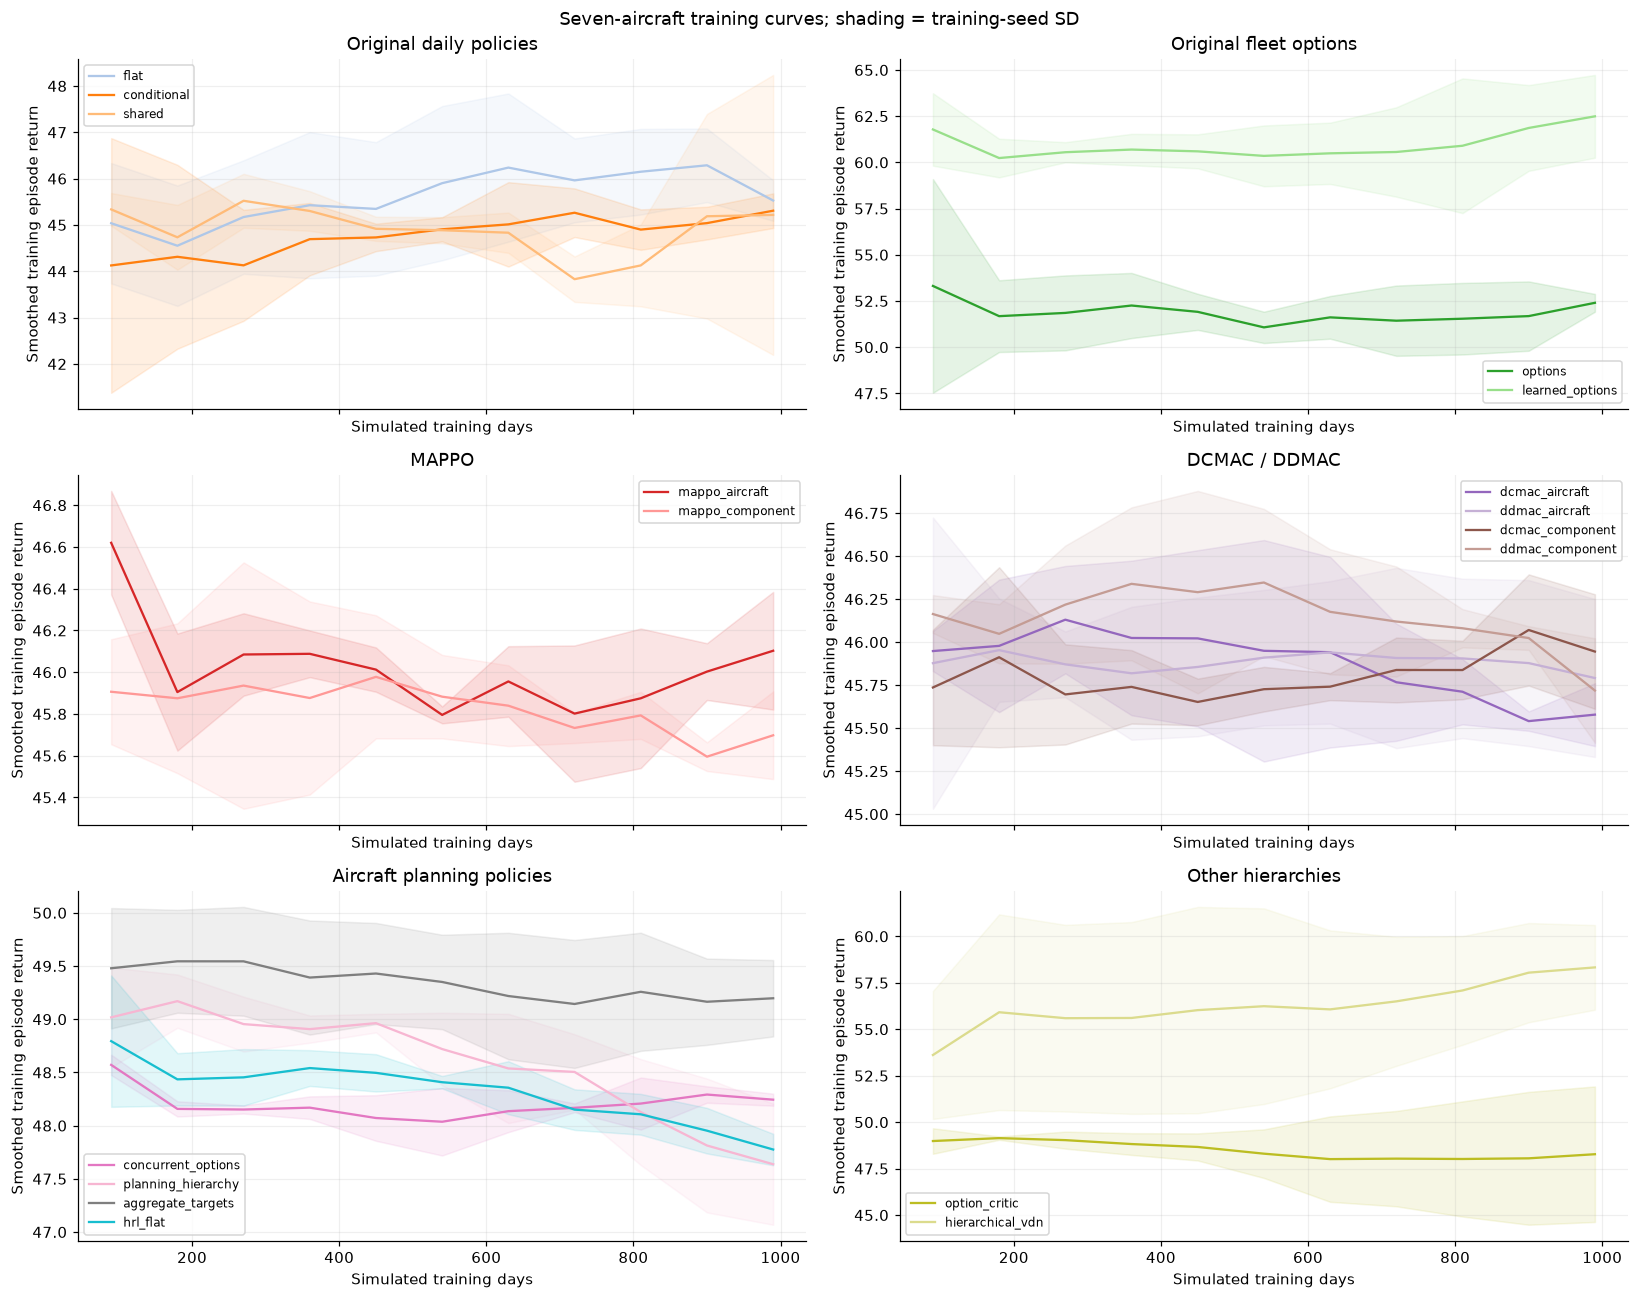

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
for ax, (group, methods) in zip(axes.flat, GROUPS.items()):
    for method in methods:
        data = curves[curves.panel.eq('fleet_7') & curves.method.eq(method)].copy()
        if data.empty: continue
        data['smoothed'] = data.groupby('training_seed').episode_return.transform(
            lambda values: values.rolling(5, min_periods=1).mean())
        # Aggregate by within-seed completed-episode index; use actual mean elapsed days on x.
        data['episode_index'] = data.groupby('training_seed').cumcount()
        points = data.groupby('episode_index').agg(days=('simulated_days', 'mean'),
                    mean=('smoothed', 'mean'), std=('smoothed', 'std')).fillna(0)
        ax.plot(points.days, points['mean'], label=method, color=COLORS[method])
        ax.fill_between(points.days, points['mean'] - points['std'],
                         points['mean'] + points['std'], color=COLORS[method], alpha=.12)
    ax.set_title(group)
    ax.set_xlabel('Simulated training days')
    ax.set_ylabel('Smoothed training episode return')
    ax.grid(alpha=.2)
    if ax.lines: ax.legend(fontsize=8)
fig.suptitle('Seven-aircraft training curves; shading = training-seed SD')
fig.tight_layout()
save_figure(fig, 'fleet_7_training_curves')

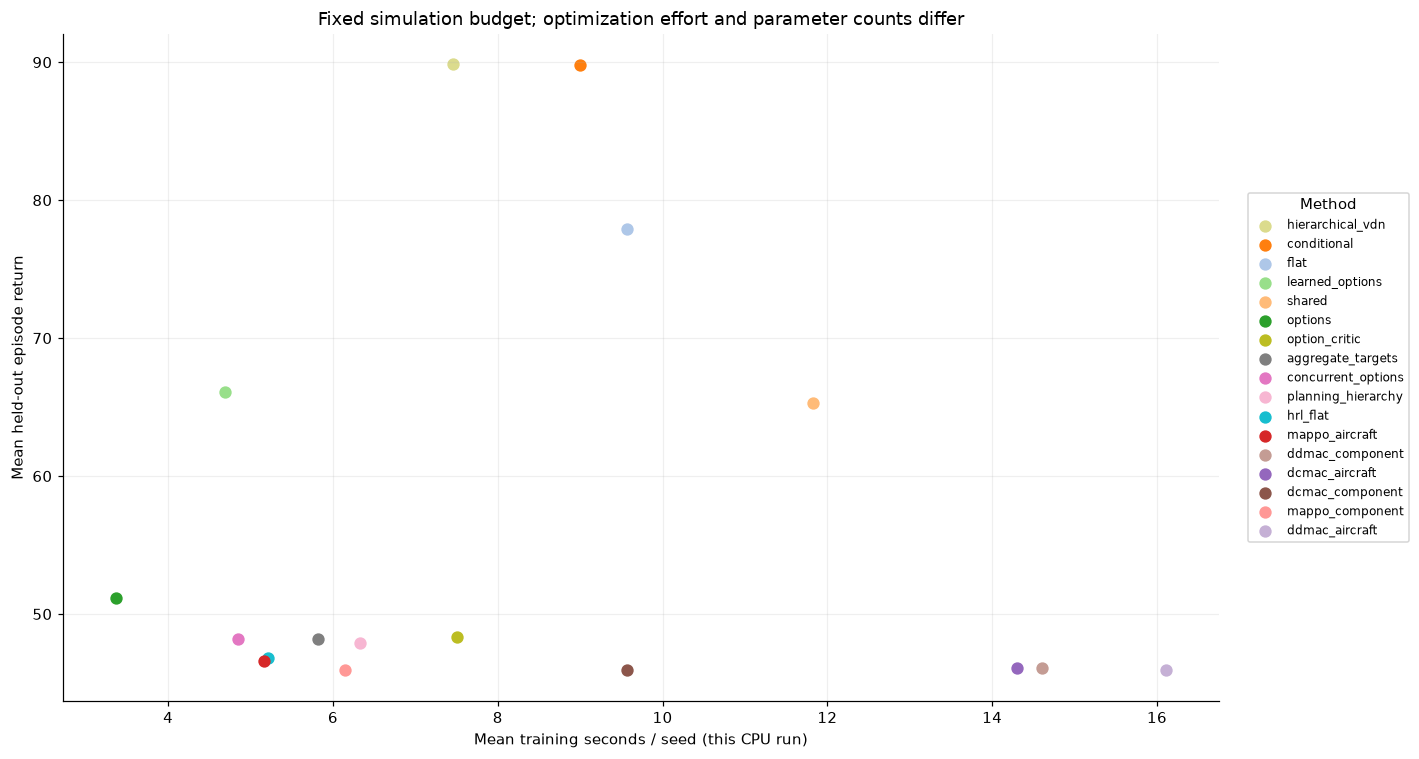

### Aircraft catalog methods relative to `hrl_flat`

,mean_delta_return,std_between_seed_pairs
method,,
planning_hierarchy,1.062,4.303
aggregate_targets,1.397,2.473
concurrent_options,1.366,0.008


Only planning_hierarchy is closely matched in authority and decision timing; all parameter counts differ.


In [8]:
fig, ax = plt.subplots(figsize=(13, 7))
data = summary[summary.panel.eq('fleet_7') & summary.method.ne('threshold')]
for row in data.itertuples():
    ax.scatter(row.training_seconds, row.return_mean, color=COLORS[row.method], s=50, label=row.method)
ax.set_xlabel('Mean training seconds / seed (this CPU run)')
ax.set_ylabel('Mean held-out episode return')
ax.set_title('Fixed simulation budget; optimization effort and parameter counts differ')
ax.grid(alpha=.2)
ax.legend(loc='center left', bbox_to_anchor=(1.02, .5), fontsize=8, title='Method')
fig.tight_layout()
save_figure(fig, 'fleet_7_return_vs_training_time')

matched = seed_means[seed_means.panel.eq('fleet_7')].pivot(
    index='training_seed', columns='method', values='return')
comparison_methods = ['planning_hierarchy', 'aggregate_targets', 'concurrent_options']
deltas = matched[comparison_methods].sub(matched['hrl_flat'], axis=0).dropna()
delta_summary = pd.DataFrame({'mean_delta_return': deltas.mean(),
                              'std_between_seed_pairs': deltas.std()})
delta_summary.index.name = 'method'
delta_summary.to_csv(RUN / 'data/catalog_comparison.csv')
display(Markdown('### Aircraft catalog methods relative to `hrl_flat`'))
display(delta_summary.round(3))
print('Only planning_hierarchy is closely matched in authority and decision timing; all parameter counts differ.')

## 6. Reload and execute a selected controller

For this demonstration, reload the best observed seven-aircraft learned controller
by mean evaluation return and execute it on additional seeds. These episodes are
kept separate from the ranking. Choosing it from the evaluation results makes it
a selection candidate; the additional episodes are a small follow-up, not a final
confirmation of superiority.

In [9]:
fleet_rank = summary[summary.panel.eq('fleet_7') & summary.method.ne('threshold')]
selected_method = fleet_rank.sort_values('return_mean', ascending=False).iloc[0].method
# Fix the training seed in advance rather than choosing the best individual checkpoint.
selected_seed = TRAIN_SEEDS[0]
checkpoint = RUN / 'checkpoints' / f'fleet_7__{selected_method}__seed{selected_seed}.pt'
loaded_cfg, loaded_method, selected_model = core.load_checkpoint(checkpoint)
demo = pd.DataFrame(core.evaluate(loaded_cfg, loaded_method, selected_model,
                                  seeds=[20000, 20001, 20002]))
demo.to_csv(RUN / 'data/selected_controller_execution.csv', index=False)
display(Markdown(f'**Reloaded controller:** `{selected_method}`, training seed `{selected_seed}`.'))
display(demo[['seed', 'return', 'availability', 'cost', 'flight_failures', 'replacements']].round(3))

**Reloaded controller:** `hierarchical_vdn`, training seed `0`.

,seed,return,availability,cost,flight_failures,replacements
0,20000,90.000,1.0,0.0,0.0,0.0
1,20001,90.000,1.0,0.0,0.0,0.0
2,20002,85.429,1.0,320.0,4.0,0.0


## 7. Results and interpretation

The following conclusions are generated from this execution's saved tables. They
are not hard-coded claims that an HRL or MARL method must win.

In [10]:
def best_row(panel, names):
    data = summary[summary.panel.eq(panel) & summary.method.isin(names)]
    return data.sort_values('return_mean', ascending=False).iloc[0]

fleet_best = best_row('fleet_7', ['threshold', *METHODS['fleet_7']])
best_marl = best_row('fleet_7', MARL)
best_hrl = best_row('fleet_7', HRL)
single_best = best_row('single_1', ['threshold', *ALL_METHODS])
single_ties = summary[summary.panel.eq('single_1') & np.isclose(summary.return_mean, single_best.return_mean, rtol=0, atol=1e-9)].method.tolist()
maxq = summary[(summary.panel == 'single_1') & (summary.method == 'maxq')].iloc[0]
baseline = summary[(summary.panel == 'fleet_7') & (summary.method == 'threshold')].iloc[0]
planning_delta = delta_summary.loc['planning_hierarchy', 'mean_delta_return']
planning_pair_signs = int((deltas['planning_hierarchy'] > 0).sum())
learned = fleet_rank.sort_values('return_mean', ascending=False)
gap = learned.iloc[0].return_mean - learned.iloc[1].return_mean
baseline_delta = learned.iloc[0].return_mean - baseline.return_mean
metric_winners = {}
for metric, ascending in [('availability_mean', False), ('cost_per_aircraft_day_mean', True),
                          ('flight_failures_mean', True)]:
    candidates = summary[summary.panel.eq('fleet_7')]
    optimum = candidates[metric].min() if ascending else candidates[metric].max()
    winners = candidates[np.isclose(candidates[metric], optimum)].method.tolist()
    metric_winners[metric] = f'all {len(winners)} methods ({optimum:g})' if len(winners) == len(candidates) else ', '.join(winners)
failure_total = int(evaluation[evaluation.panel.eq('fleet_7')].flight_failures.sum())
best_learned = learned.iloc[0]
availability_contribution = HORIZON * (best_learned.availability_mean - baseline.availability_mean)
cost_contribution = -HORIZON / 10 * (best_learned.cost_per_aircraft_day_mean - baseline.cost_per_aircraft_day_mean)
assert np.isclose(availability_contribution + cost_contribution, baseline_delta)

conclusion = f'''### Observed outcome

- **Highest seven-aircraft mean return:** `{fleet_best.method}` ({fleet_best.return_mean:.2f}).
- **Best observed MARL method:** `{best_marl.method}` ({best_marl.return_mean:.2f}; training-seed SD {best_marl.return_std:.2f}).
- **Best observed HRL method:** `{best_hrl.method}` ({best_hrl.return_mean:.2f}; training-seed SD {best_hrl.return_std:.2f}).
- The top learned controller is **{baseline_delta:+.2f} return units relative to the threshold rule**. Its lead over the second learned controller is {gap:.2f}; this is descriptive, not a significance test.
- **One-aircraft result:** {len(single_ties)} methods tie at the highest mean return ({single_best.return_mean:.2f}); MAXQ ranks {int(maxq.rank_by_return)} of {len(ALL_METHODS)+1}, with return {maxq.return_mean:.2f}. This panel cannot establish fleet scalability.

### Does explicit hierarchy help in the closer comparison?

`planning_hierarchy - hrl_flat` is **{planning_delta:+.2f} mean return units**, positive in {planning_pair_signs}/{len(TRAIN_SEEDS)} paired training seeds. The two methods share the catalog, broker, information and duration accounting; network parameterization and size still differ. Other method comparisons also change decision authority, update rules or timing.

### What explains the scores?

Highest availability: **{metric_winners['availability_mean']}**. Lowest cost per aircraft-day: **{metric_winners['cost_per_aircraft_day_mean']}**. Fewest failed flights: **{metric_winners['flight_failures_mean']}**. Inspect these alongside replacements and training curves: a return lead can arise from a different availability/maintenance trade-off, rather than a universally better maintenance policy.

The top learned controller's return difference from the threshold rule decomposes exactly into **{availability_contribution:+.2f} units from flown availability** and **{cost_contribution:+.2f} units from total cost**. This follows the simulator identity `episode return = horizon * availability - cost / (10 * aircraft)`; it is an accounting explanation rather than a causal architecture claim.

The leading learned controller averages **{best_learned.replacements_mean:.2f} replacements and {best_learned.availability_mean:.1%} availability**. The leading MARL controller averages **{best_marl.replacements_mean:.2f} replacements and {best_marl.availability_mean:.1%} availability**; the leading HRL controller averages **{best_hrl.replacements_mean:.2f} replacements and {best_hrl.availability_mean:.1%} availability**. These observed maintenance/grounding differences help explain the return differences. Different categorical action spaces and limited training are possible contributors that this experiment does not isolate.

The finite **{HORIZON}-day horizon**, initially high health, and absence of a terminal charge for remaining degradation can favor policies that defer maintenance beyond the evaluated episode. A score close to {HORIZON} approaches this environment's return ceiling. Inspect failures and replacement counts, and extend the horizon or test more degraded initial states consistently across methods before interpreting such a score as a strong lifetime maintenance policy.

### Limits and next decision

This run uses **{TRAIN_DAYS:,} simulated training days per seed, {len(TRAIN_SEEDS)} training seeds and {len(EVAL_SEEDS)} held-out episodes per trained model**. Error bars show training-seed variation, not confidence intervals or all evaluation uncertainty. Only {failure_total} failed-flight occurrences were recorded across the seven-aircraft evaluation rows; these rows reuse scenarios across methods, so that total is not an independent estimate of a real-world failure rate. Zero observed failures leave failure-risk performance unresolved in this pilot.

The current candidate for a longer fleet experiment is `{selected_method}` by observed learned-policy return. Extend the budget and seed count and check performance on fresh evaluation scenarios before claiming a winner. All controllers use the current synthetic physical model; no hot-weather, dust, salt or flight-hour upgrade was introduced by this notebook. Results reflect the method implementations in this repository, not a ranking of the original papers' algorithms.
'''
display(Markdown(conclusion))
(RUN / 'results_interpretation.md').write_text(conclusion, encoding='utf-8')
manifest['status'] = 'complete'
manifest['completed_training_runs'] = len(runs)
manifest['evaluation_rows'] = len(evaluation)
manifest['selected_fleet_controller'] = selected_method
manifest['runtime_note'] = 'Sequential local CPU runs; training time excludes evaluation and serialization.'
save_json(RUN / 'manifest.json', manifest)
save_json(RUN / 'verification.json', {'all_methods_covered': set(evaluation.method) == {'threshold', *ALL_METHODS},
    'all_checkpoint_reloads_verified': bool(runs.reload_verified.all()),
    'training_runs': len(runs), 'evaluation_rows': len(evaluation),
    'no_duplicate_evaluation_keys': True, 'all_returns_finite': True,
    'comparison_figure_panels': ['fleet_7', 'single_1'], 'core_sha256': SOURCE_HASH})
print('Saved:', RUN.relative_to(PROJECT))
print('Tables: data/ | Figures: plots/ | Local weights: checkpoints/ | Local logs: training_logs/')

### Observed outcome

- **Highest seven-aircraft mean return:** `hierarchical_vdn` (89.83).
- **Best observed MARL method:** `mappo_aircraft` (46.62; training-seed SD 0.42).
- **Best observed HRL method:** `hierarchical_vdn` (89.83; training-seed SD 0.00).
- The top learned controller is **+29.16 return units relative to the threshold rule**. Its lead over the second learned controller is 0.02; this is descriptive, not a significance test.
- **One-aircraft result:** 16 methods tie at the highest mean return (90.00); MAXQ ranks 1 of 19, with return 90.00. This panel cannot establish fleet scalability.

### Does explicit hierarchy help in the closer comparison?

`planning_hierarchy - hrl_flat` is **+1.06 mean return units**, positive in 1/3 paired training seeds. The two methods share the catalog, broker, information and duration accounting; network parameterization and size still differ. Other method comparisons also change decision authority, update rules or timing.

### What explains the scores?

Highest availability: **hierarchical_vdn, conditional**. Lowest cost per aircraft-day: **hierarchical_vdn**. Fewest failed flights: **all 18 methods (0)**. Inspect these alongside replacements and training curves: a return lead can arise from a different availability/maintenance trade-off, rather than a universally better maintenance policy.

The top learned controller's return difference from the threshold rule decomposes exactly into **+16.53 units from flown availability** and **+12.63 units from total cost**. This follows the simulator identity `episode return = horizon * availability - cost / (10 * aircraft)`; it is an accounting explanation rather than a causal architecture claim.

The leading learned controller averages **0.05 replacements and 99.9% availability**. The leading MARL controller averages **41.22 replacements and 71.4% availability**; the leading HRL controller averages **0.05 replacements and 99.9% availability**. These observed maintenance/grounding differences help explain the return differences. Different categorical action spaces and limited training are possible contributors that this experiment does not isolate.

The finite **90-day horizon**, initially high health, and absence of a terminal charge for remaining degradation can favor policies that defer maintenance beyond the evaluated episode. A score close to 90 approaches this environment's return ceiling. Inspect failures and replacement counts, and extend the horizon or test more degraded initial states consistently across methods before interpreting such a score as a strong lifetime maintenance policy.

### Limits and next decision

This run uses **1,024 simulated training days per seed, 3 training seeds and 20 held-out episodes per trained model**. Error bars show training-seed variation, not confidence intervals or all evaluation uncertainty. Only 0 failed-flight occurrences were recorded across the seven-aircraft evaluation rows; these rows reuse scenarios across methods, so that total is not an independent estimate of a real-world failure rate. Zero observed failures leave failure-risk performance unresolved in this pilot.

The current candidate for a longer fleet experiment is `hierarchical_vdn` by observed learned-policy return. Extend the budget and seed count and check performance on fresh evaluation scenarios before claiming a winner. All controllers use the current synthetic physical model; no hot-weather, dust, salt or flight-hour upgrade was introduced by this notebook. Results reflect the method implementations in this repository, not a ranking of the original papers' algorithms.


Saved: results\presentation_20261026T143049Z
Tables: data/ | Figures: plots/ | Local weights: checkpoints/ | Local logs: training_logs/
